In [2]:
pip install matplotlib seaborn

   ---------------------------------------- 0.0/7.8 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/7.8 MB 7.2 MB/s eta 0:00:01
   ------------ --------------------------- 2.4/7.8 MB 6.7 MB/s eta 0:00:01
   ----------------- ---------------------- 3.4/7.8 MB 6.3 MB/s eta 0:00:01
   ---------------------- ----------------- 4.5/7.8 MB 5.8 MB/s eta 0:00:01
   ------------------------- -------------- 5.0/7.8 MB 5.5 MB/s eta 0:00:01
   ------------------------------ --------- 6.0/7.8 MB 5.1 MB/s eta 0:00:01
   ---------------------------------- ----- 6.8/7.8 MB 5.0 MB/s eta 0:00:01
   ------------------------------------ --- 7.1/7.8 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 7.8/7.8 MB 4.4 MB/s  0:00:01
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------------- -------------------------- 0.5/1.5 MB 2.8 MB/s eta 0:00:01
   -------------------- ------------------- 0.8/1.5 MB 2.6 MB/s eta 0:00:01
   --------------------------

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

movies = pd.read_csv(
    r"c:\xampp\perl\vendor\lib\auto\Devel\vscode\TMDB_data\cleaned_movies.csv"
)

genres = pd.read_csv(
    r"c:\xampp\perl\vendor\lib\auto\Devel\vscode\TMDB_data\cleaned_genres.csv"
)

movie_genres = pd.read_csv(
    r"c:\xampp\perl\vendor\lib\auto\Devel\vscode\TMDB_data\cleaned_movie_genres.csv"
)

cast = pd.read_csv(
    r"c:\xampp\perl\vendor\lib\auto\Devel\vscode\TMDB_data\cleaned_cast.csv"
)

crew = pd.read_csv(
    r"c:\xampp\perl\vendor\lib\auto\Devel\vscode\TMDB_data\cleaned_crew.csv"
)

movie_keywords = pd.read_csv(
    r"c:\xampp\perl\vendor\lib\auto\Devel\vscode\TMDB_data\cleaned_movie_keywords.csv"
)

movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

movies["release_year"] = movies["release_date"].dt.year

print("Datasets loaded successfully!")

Datasets loaded successfully!


1. Univariate Analysis

Distribution of Movie Budgets

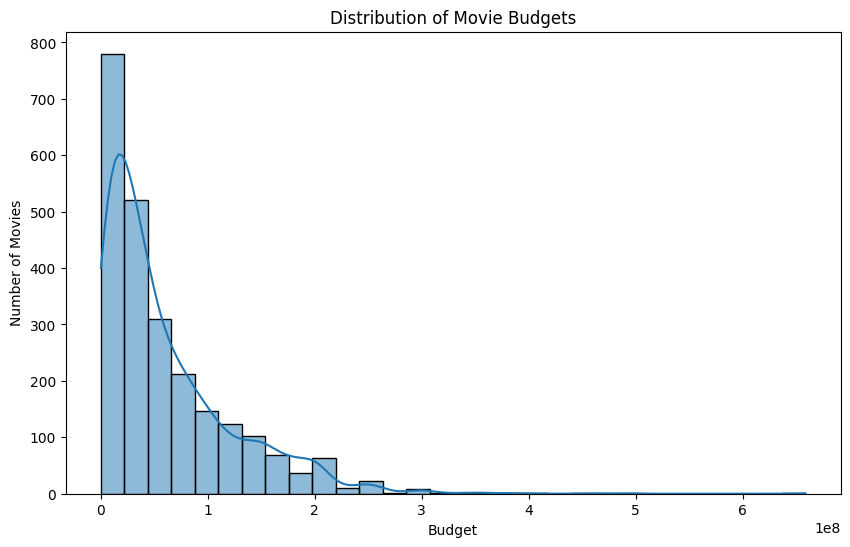

In [4]:
budget_data = movies[movies["budget"] > 0]

plt.figure(figsize=(10, 6))

sns.histplot(
    budget_data["budget"],
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Budgets")
plt.xlabel("Budget")
plt.ylabel("Number of Movies")

plt.show()

Chart 2: Distribution of Movie Runtime

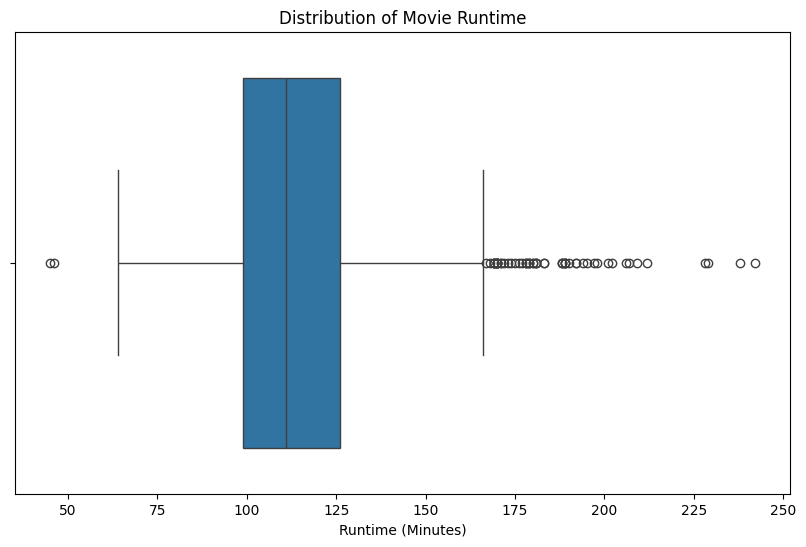

In [5]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=movies["runtime"].dropna()
)

plt.title("Distribution of Movie Runtime")

plt.xlabel("Runtime (Minutes)")

plt.show()

Chart 3: Distribution of Movie Ratings

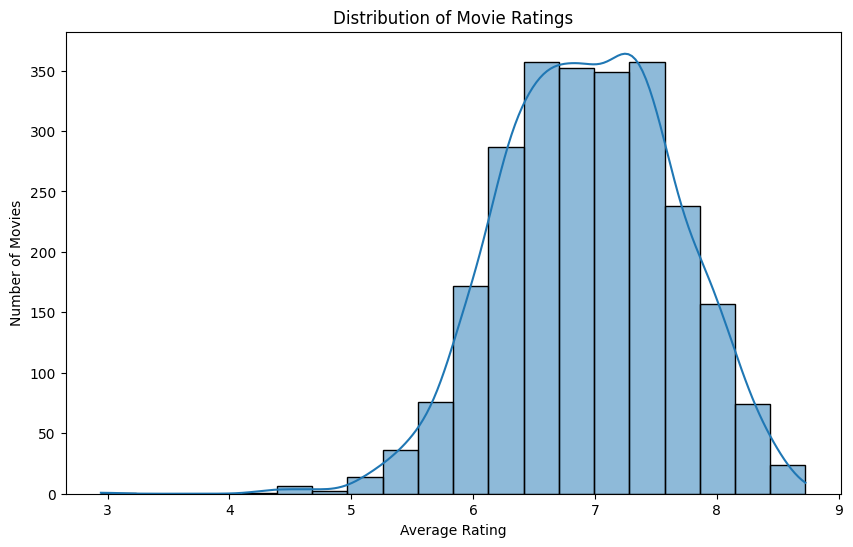

In [6]:
plt.figure(figsize=(10, 6))

sns.histplot(
    movies["vote_average"].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Ratings")

plt.xlabel("Average Rating")

plt.ylabel("Number of Movies")

plt.show()

Chart 4: Number of Movies per Genre

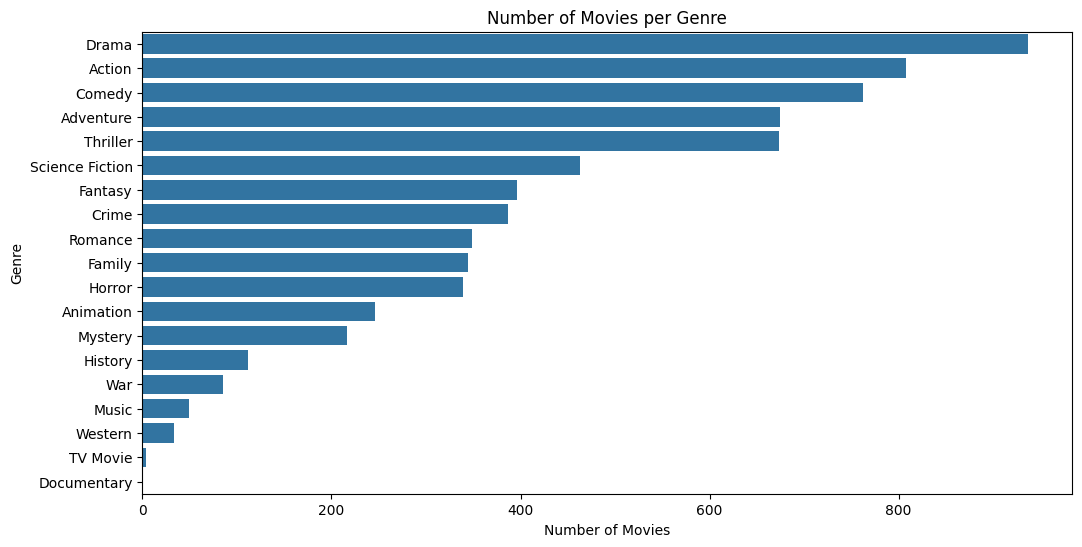

In [7]:
genre_counts = (
    movie_genres
    .merge(genres, on="genre_id")
    .groupby("genre_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies per Genre")

plt.xlabel("Number of Movies")

plt.ylabel("Genre")

plt.show()

2. Bivariate Analysis

Chart 5: Budget vs Revenue

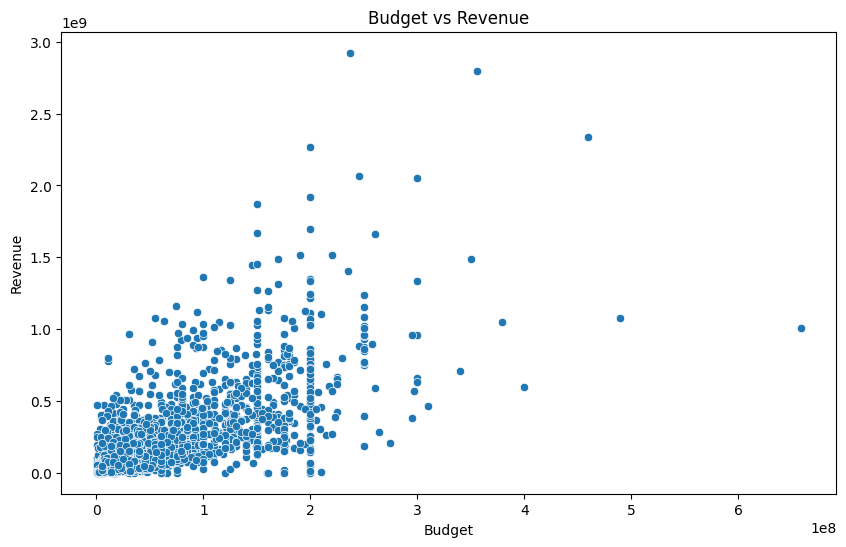

In [8]:
financial_movies = movies[
    (movies["budget"] > 0)
    & (movies["revenue"] > 0)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=financial_movies,
    x="budget",
    y="revenue"
)

plt.title("Budget vs Revenue")

plt.xlabel("Budget")

plt.ylabel("Revenue")

plt.show()

Chart 6: Popularity vs Vote Count

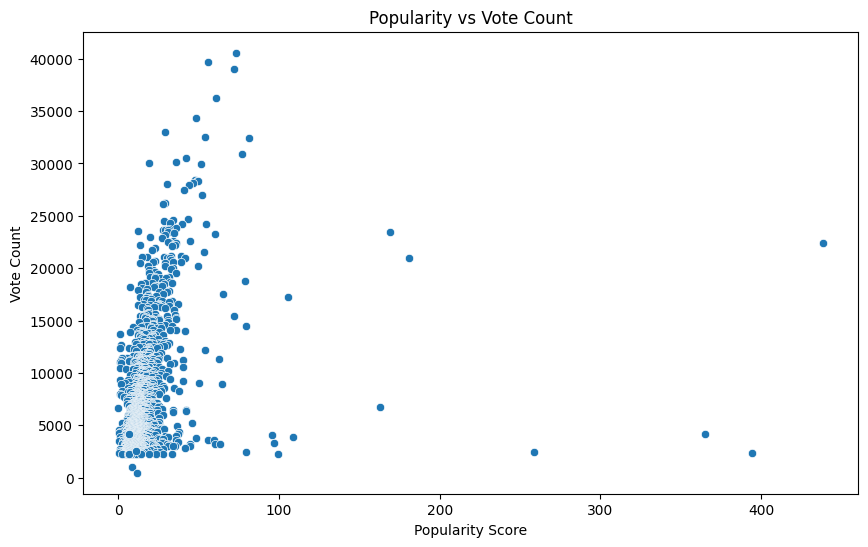

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=movies,
    x="popularity",
    y="vote_count"
)

plt.title("Popularity vs Vote Count")

plt.xlabel("Popularity Score")

plt.ylabel("Vote Count")

plt.show()

Chart 7: Average Rating by Genre

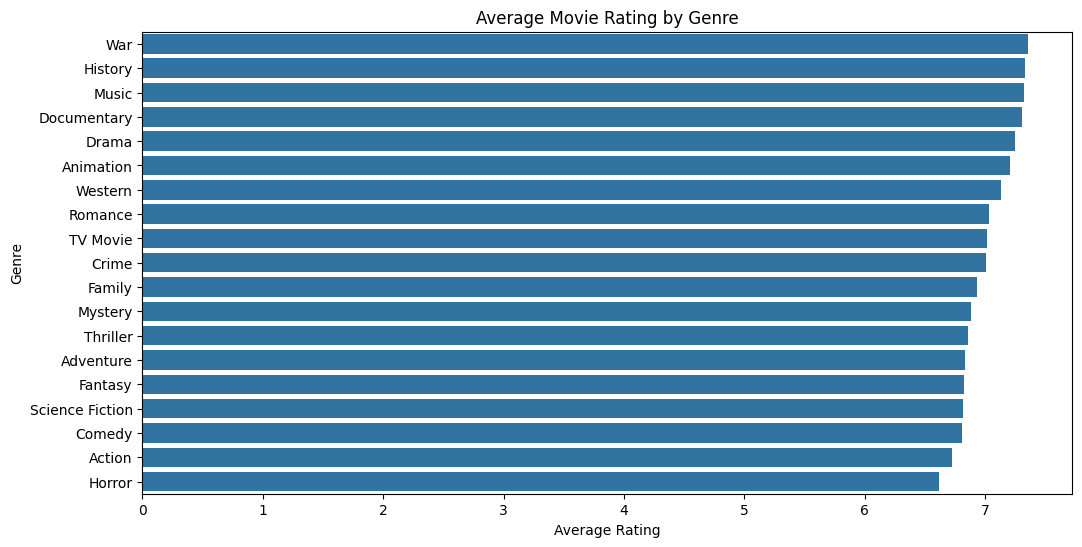

In [10]:
genre_rating = (
    movie_genres
    .merge(genres, on="genre_id")
    .merge(
        movies[["movie_id", "vote_average"]],
        on="movie_id"
    )
    .groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_rating.values,
    y=genre_rating.index
)

plt.title("Average Movie Rating by Genre")

plt.xlabel("Average Rating")

plt.ylabel("Genre")

plt.show()

Chart 8: Number of Movies Released per Year

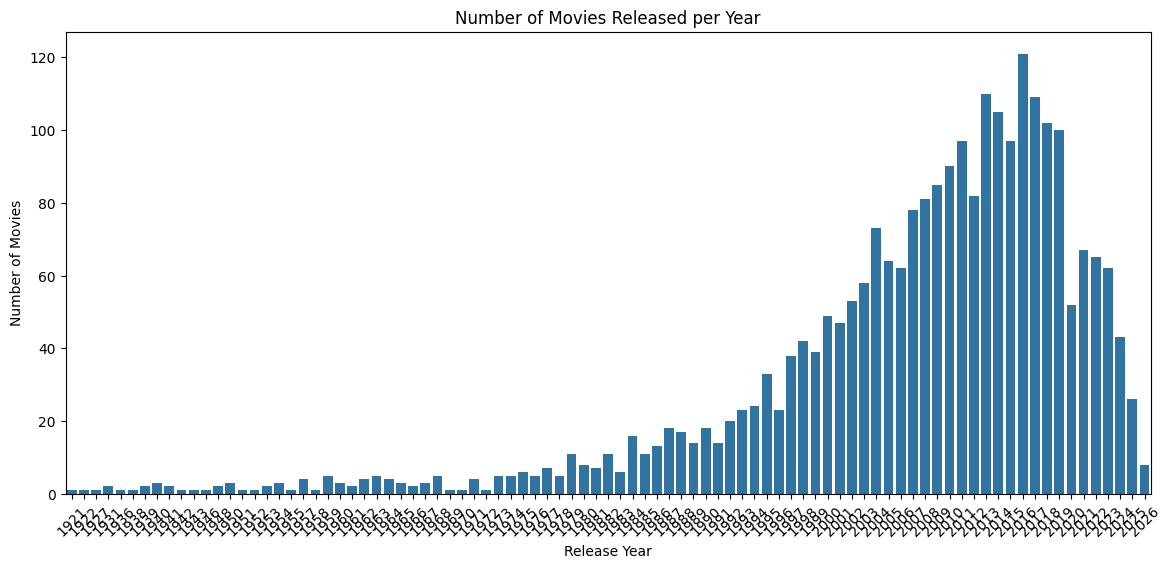

In [11]:
year_counts = (
    movies
    .groupby("release_year")
    .size()
    .reset_index(name="movie_count")
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=year_counts,
    x="release_year",
    y="movie_count"
)

plt.title("Number of Movies Released per Year")

plt.xlabel("Release Year")

plt.ylabel("Number of Movies")

plt.xticks(rotation=45)

plt.show()

3. Multivariate Analysis

Chart 9: Budget vs Revenue by Rating

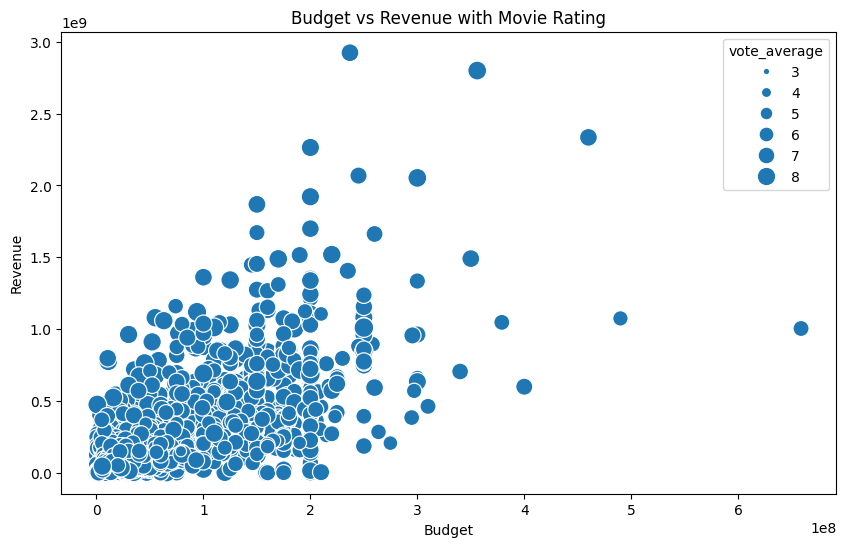

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=financial_movies,
    x="budget",
    y="revenue",
    size="vote_average",
    sizes=(20, 200)
)

plt.title("Budget vs Revenue with Movie Rating")

plt.xlabel("Budget")

plt.ylabel("Revenue")

plt.show()

Chart 10: Genre, Popularity and Rating

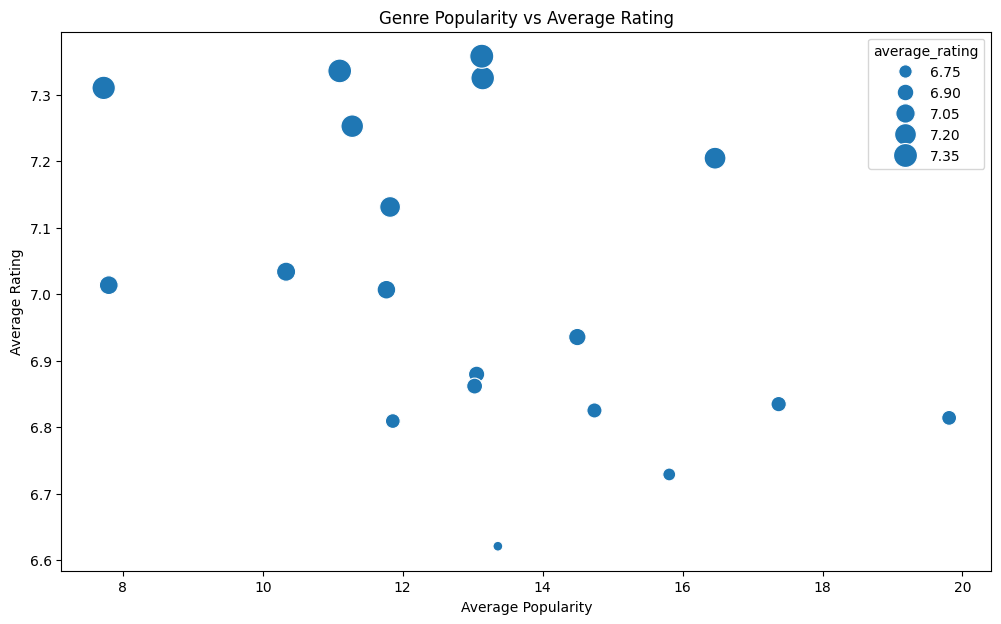

In [14]:
genre_metrics = (
    movie_genres
    .merge(genres, on="genre_id")
    .merge(
        movies[
            [
                "movie_id",
                "popularity",
                "vote_average"
            ]
        ],
        on="movie_id"
    )
    .groupby("genre_name")
    .agg(
        average_popularity=(
            "popularity",
            "mean"
        ),
        average_rating=(
            "vote_average",
            "mean"
        )
    )
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=genre_metrics,
    x="average_popularity",
    y="average_rating",
    size="average_rating",
    sizes=(50, 300)
)

plt.title("Genre Popularity vs Average Rating")

plt.xlabel("Average Popularity")

plt.ylabel("Average Rating")

plt.show()